In [47]:
import os
if not os.path.exists("fruits-360-100x100"):
    !git clone --depth 1 https://github.com/fruits-360/fruits-360-100x100.git
print(os.listdir("fruits-360-100x100"))

['.git', 'LICENSE', 'README.md', 'Test', 'Training']


Cloning into 'fruits-360-100x100'...
Updating files:   0% (1579/191812)
Updating files:   1% (1919/191812)
Updating files:   1% (3135/191812)
Updating files:   2% (3837/191812)
Updating files:   2% (4635/191812)
Updating files:   3% (5755/191812)
Updating files:   3% (6238/191812)
Updating files:   4% (7673/191812)
Updating files:   4% (7884/191812)
Updating files:   4% (9376/191812)
Updating files:   5% (9591/191812)
Updating files:   5% (11068/191812)
Updating files:   6% (11509/191812)
Updating files:   6% (12634/191812)
Updating files:   7% (13427/191812)
Updating files:   7% (14206/191812)
Updating files:   8% (15345/191812)
Updating files:   8% (15862/191812)
Updating files:   9% (17264/191812)
Updating files:   9% (17534/191812)
Updating files:  10% (19182/191812)
Updating files:  10% (19251/191812)
Updating files:  10% (20901/191812)
Updating files:  11% (21100/191812)
Updating files:  11% (22591/191812)
Updating files:  12% (23018/191812)
Updating files:  12% (24441/191812)
Up

In [48]:
DATA_DIR = "fruits-360-100x100" 
TRAIN_DIR = os.path.join(DATA_DIR, "Training")
TEST_DIR = os.path.join(DATA_DIR, "Test")

print(len(os.listdir(TRAIN_DIR)), "classes in Training")
print(len(os.listdir(TEST_DIR)), "classes in Test")

269 classes in Training
269 classes in Test


## Settings
Run cell ONCE, don't re-run it between experiments.

In [49]:
import random

N_CLASSES = 270       # number of fruit classes to use (270 = all)
EPOCHS_HEAD = 3      # epochs with the pre-trained part frozen
EPOCHS_FINE = 3      # epochs while fine-tuning
SEED = 42

all_classes = sorted(os.listdir(TRAIN_DIR))
if N_CLASSES >= len(all_classes):
    chosen = all_classes
else:
    chosen = sorted(random.Random(SEED).sample(all_classes, N_CLASSES))

# ignore capitals
test_lookup = {name.lower(): name for name in os.listdir(TEST_DIR)}
chosen_test = [test_lookup[name.lower()] for name in chosen]
for a, b in zip(chosen, chosen_test):
    if a != b:
        print("name differs:", a, "vs", b)

results = []         # experiment log 
histories = {}       # history of each experiment
os.makedirs("results", exist_ok=True)
print(len(chosen), "classes chosen")

name differs: BlackBerry 4 vs Blackberry 4
269 classes chosen


## Load Data

In [50]:
%pip install -q scikit-learn matplotlib seaborn pandas
import tensorflow as tf
IMG = (224, 224); BS = 32
INPUT_SHAPE = IMG + (3,)
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, class_names=chosen, validation_split=0.2, subset="training", seed=42,
    image_size=IMG, batch_size=BS)
val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, class_names=chosen, validation_split=0.2, subset="validation", seed=42,
    image_size=IMG, batch_size=BS)
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, class_names=chosen_test, image_size=IMG, batch_size=BS, shuffle=False)
class_names = train_ds.class_names
print(len(class_names), "classes used")


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Found 143879 files belonging to 269 classes.
Using 115104 files for training.
Found 143879 files belonging to 269 classes.
Using 28775 files for validation.
Found 47931 files belonging to 269 classes.
269 classes used


## Data Exploration

In [51]:
import pandas as pd
import matplotlib.pyplot as plt

# How many training images does each class have?
counts = pd.Series({c: len(os.listdir(os.path.join(TRAIN_DIR, c))) for c in chosen})
print("Images per class (Training folder):")
print("  min :", counts.min(), "->", counts.idxmin())
print("  max :", counts.max(), "->", counts.idxmax())
print("  mean:", round(counts.mean(), 1))

Images per class (Training folder):
  min : 144 -> Cabbage white 1
  max : 984 -> Grape Blue 1
  mean: 534.9


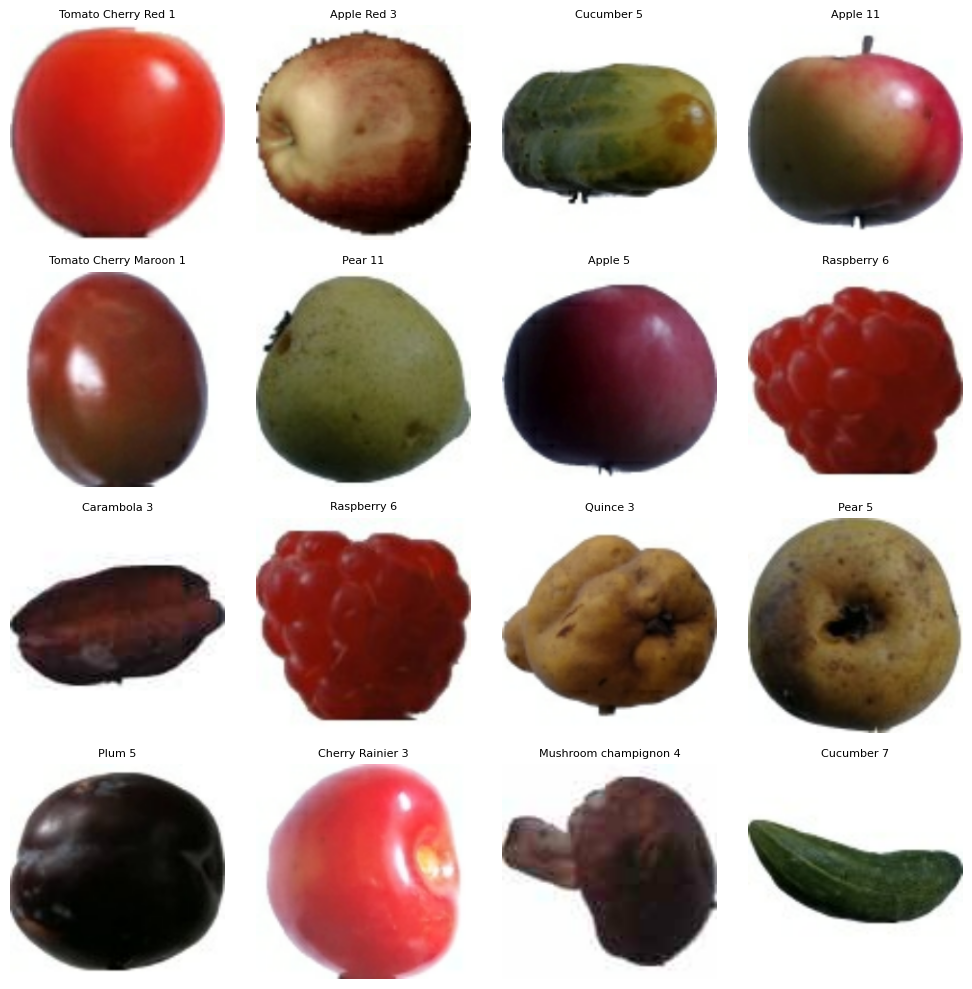

In [52]:
# Visualize some sample images from the training dataset
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(16):
        plt.subplot(4, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()], fontsize=8)
        plt.axis("off")
plt.tight_layout()
plt.savefig("results/sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

## Data Augmentation

In [53]:
from tensorflow.keras import layers

augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

## Models

In [96]:
import time
from tensorflow.keras.applications import EfficientNetB0, ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

# ----- EXPERIMENT SETTINGS: change ONE thing at a time, then run this cell -----
EXPERIMENT_NAME = "EfficientNetB0, augmentation, unfreeze 60"
BACKBONE = "efficientnet"    # "efficientnet" or "resnet50"
USE_AUG = True               # True = augment the training images
DROPOUT = 0.3                # randomly switches off 30% of neurons while training to reduce overfitting
LR_FINE = 1e-5               # learning rate during fine-tuning
UNFREEZE = 60                # how many of the last layers of the pre-trained model to fine-tune
# -------------------------------------------------------------------------------

# 1. Load the pre-trained model, without its original classifier on top
if BACKBONE == "efficientnet":
    base_model = EfficientNetB0(include_top=False, weights="imagenet", input_shape=INPUT_SHAPE)
    preprocess = None                  
    last_conv = "top_activation"       # last convolution layer, used by Grad-CAM
else:
    base_model = ResNet50(include_top=False, weights="imagenet", input_shape=INPUT_SHAPE)
    preprocess = resnet_preprocess     # ResNet needs pixel scaling
    last_conv = "conv5_block3_out"

# 2. Prepare the data (augmentation only on training data)
def prepare(ds, augmenting=False):
    if augmenting:
        ds = ds.map(lambda x, y: (augment(x, training=True), y),
                    num_parallel_calls=tf.data.AUTOTUNE)
    if preprocess is not None:
        ds = ds.map(lambda x, y: (preprocess(x), y),
                    num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_data = prepare(train_ds, USE_AUG)
val_data = prepare(val_ds)
test_data = prepare(test_ds)

# 3. Freeze the pre-trained part and add own classifier on top
base_model.trainable = False
x = layers.GlobalAveragePooling2D()(base_model.output)
x = layers.Dropout(DROPOUT)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)   # one output per fruit class
model = tf.keras.Model(base_model.input, outputs)

# 4. Phase 1: train only the new classifier
start = time.time()
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_head = model.fit(train_data, validation_data=val_data, epochs=EPOCHS_HEAD)

# 5. Phase 2: unfreeze the last layers and fine-tune with a small learning rate
base_model.trainable = True
for layer in base_model.layers[:-UNFREEZE]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False          
model.compile(optimizer=tf.keras.optimizers.Adam(LR_FINE),     # must compile again after changing trainable
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_fine = model.fit(train_data, validation_data=val_data, epochs=EPOCHS_FINE)
minutes = (time.time() - start) / 60

# 6. Test set result, saved to the results table
test_loss, test_acc = model.evaluate(test_data)
results.append({
    "experiment": EXPERIMENT_NAME,
    "classes": len(class_names),
    "val_acc": round(max(history_fine.history["val_accuracy"]), 4),
    "test_acc": round(test_acc, 4),
    "minutes": round(minutes, 1),
    "train_acc": round(history_fine.history["accuracy"][-1], 4),
    "gap": round(history_fine.history["accuracy"][-1] - history_fine.history["val_accuracy"][-1], 4),
    "val_loss": round(history_fine.history["val_loss"][-1], 4),
    "test_loss": round(test_loss, 4),
})

harder = tf.keras.Sequential([
    layers.RandomRotation(0.15), layers.RandomZoom(0.2),
    layers.RandomBrightness(0.4), layers.RandomContrast(0.4),
])
shifted = test_ds.map(lambda x, y: (harder(x, training=True), y))
if preprocess is not None:
    shifted = shifted.map(lambda x, y: (preprocess(x), y))
altered_acc = model.evaluate(shifted)[1]
results[-1]["altered_acc"] = round(altered_acc, 4)

print(f"{EXPERIMENT_NAME}: test accuracy {test_acc:.4f}, altered-image accuracy {altered_acc:.4f}, time {minutes:.1f} min")

histories[EXPERIMENT_NAME] = {
    "acc": history_head.history["accuracy"] + history_fine.history["accuracy"],
    "val_acc": history_head.history["val_accuracy"] + history_fine.history["val_accuracy"],
    "loss": history_head.history["loss"] + history_fine.history["loss"],
    "val_loss": history_head.history["val_loss"] + history_fine.history["val_loss"],
}

Epoch 1/3
3597/3597 ━━━━━━━━━━━━━━━━━━━━ 1410s 390ms/step - accuracy: 0.9071 - loss: 0.5474 - val_accuracy: 0.9905 - val_loss: 0.0740
Epoch 2/3
3597/3597 ━━━━━━━━━━━━━━━━━━━━ 1349s 375ms/step - accuracy: 0.9835 - loss: 0.0828 - val_accuracy: 0.9959 - val_loss: 0.0292
Epoch 3/3
3597/3597 ━━━━━━━━━━━━━━━━━━━━ 1343s 373ms/step - accuracy: 0.9881 - loss: 0.0500 - val_accuracy: 0.9974 - val_loss: 0.0183
Epoch 1/3
3597/3597 ━━━━━━━━━━━━━━━━━━━━ 1625s 450ms/step - accuracy: 0.9940 - loss: 0.0215 - val_accuracy: 0.9994 - val_loss: 0.0054
Epoch 2/3
3597/3597 ━━━━━━━━━━━━━━━━━━━━ 1628s 453ms/step - accuracy: 0.9962 - loss: 0.0133 - val_accuracy: 0.9994 - val_loss: 0.0040
Epoch 3/3
3597/3597 ━━━━━━━━━━━━━━━━━━━━ 1651s 459ms/step - accuracy: 0.9972 - loss: 0.0100 - val_accuracy: 0.9999 - val_loss: 0.0029
1498/1498 ━━━━━━━━━━━━━━━━━━━━ 449s 300ms/step - accuracy: 0.9940 - loss: 0.0235
1498/1498 ━━━━━━━━━━━━━━━━━━━━ 547s 365ms/step - accuracy: 0.8411 - loss: 0.8935
EfficientNetB0, augmentation, unfr

## Training Curves

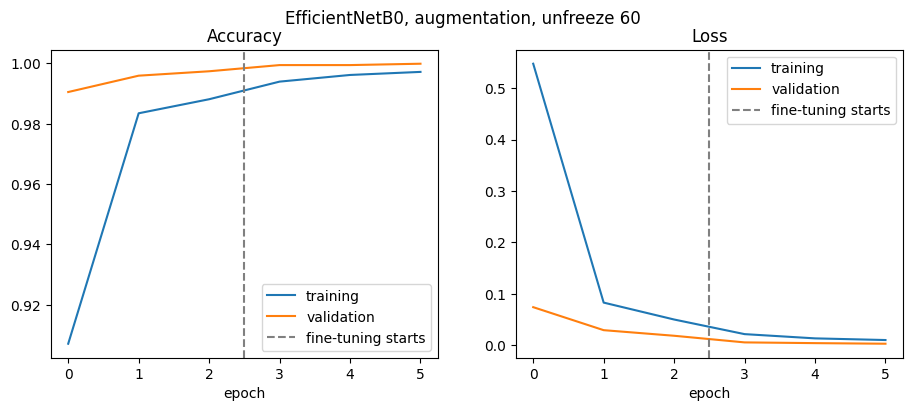

In [97]:
import matplotlib.pyplot as plt

acc = history_head.history["accuracy"] + history_fine.history["accuracy"]
val_acc = history_head.history["val_accuracy"] + history_fine.history["val_accuracy"]
loss = history_head.history["loss"] + history_fine.history["loss"]
val_loss = history_head.history["val_loss"] + history_fine.history["val_loss"]
fine_start = len(history_head.history["accuracy"]) - 0.5     # epoch where fine-tuning begins

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(acc, label="training")
ax1.plot(val_acc, label="validation")
ax1.set_title("Accuracy")
ax2.plot(loss, label="training")
ax2.plot(val_loss, label="validation")
ax2.set_title("Loss")
for ax in (ax1, ax2):
    ax.axvline(fine_start, linestyle="--", color="gray", label="fine-tuning starts")
    ax.set_xlabel("epoch")
    ax.legend()
fig.suptitle(EXPERIMENT_NAME)
plt.savefig(f"results/curve_{EXPERIMENT_NAME}.png", dpi=150, bbox_inches="tight")
plt.show()

## Compare

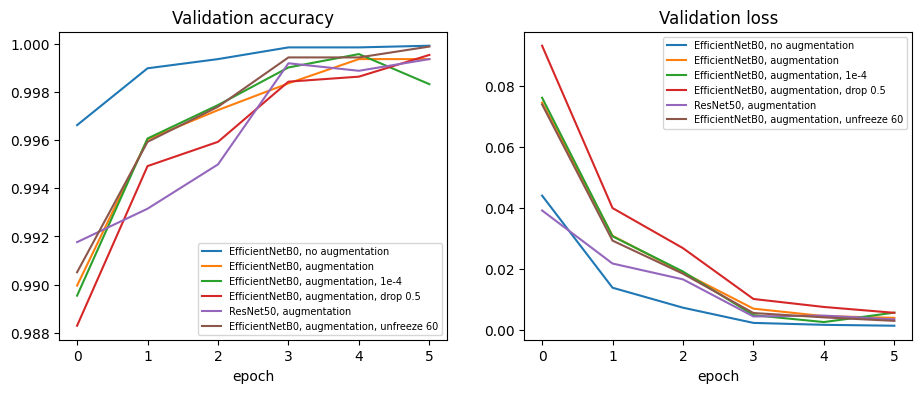

In [98]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for name, h in histories.items():
    ax1.plot(h["val_acc"], label=name)
    ax2.plot(h["val_loss"], label=name)
ax1.set_title("Validation accuracy"); ax2.set_title("Validation loss")
for ax in (ax1, ax2):
    ax.set_xlabel("epoch"); ax.legend(fontsize=7)
plt.savefig(f"results/compare_{EXPERIMENT_NAME}.png", dpi=150, bbox_inches="tight")
plt.show()

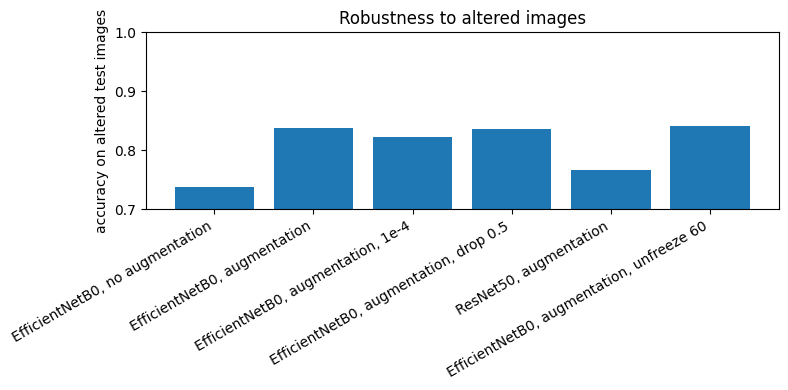

In [99]:
df = pd.DataFrame(results)
plt.figure(figsize=(8, 4))
plt.bar(df["experiment"], df["altered_acc"])
plt.xticks(rotation=30, ha="right")
plt.ylabel("accuracy on altered test images")
plt.ylim(0.7, 1.0)          # zoom
plt.title("Robustness to altered images")
plt.tight_layout()
plt.savefig("results/compare_altered.png", dpi=150)
plt.show()

## Error Analysis

In [100]:
import numpy as np, pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.concatenate([y.numpy() for _, y in test_data])        # real labels
y_pred = np.argmax(model.predict(test_data), axis=1)               # predicted labels

report = pd.DataFrame(classification_report(
    y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0)).T
print("Weakest 10 classes:")
print(report.iloc[:-3].sort_values("f1-score").head(10)[["precision", "recall", "f1-score"]])

cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))
np.fill_diagonal(cm, 0)                                             # ignore the correct predictions
pairs = [(class_names[i], class_names[j], cm[i, j]) for i, j in zip(*np.nonzero(cm))]
print("\nMost confused pairs (true class -> predicted class: count):")
for true_name, pred_name, count in sorted(pairs, key=lambda p: -p[2])[:10]:
    print(f"  {true_name} -> {pred_name}: {count}")

1498/1498 ━━━━━━━━━━━━━━━━━━━━ 487s 324ms/step
Weakest 10 classes:
                  precision    recall  f1-score
Corn 1             1.000000  0.766667  0.867925
Apple Red 2        1.000000  0.798780  0.888136
Eggplant 1         1.000000  0.807692  0.893617
Corn Husk 1        1.000000  0.811688  0.896057
Apple Braeburn 1   0.849741  1.000000  0.918768
Tomato Heart 1     1.000000  0.864035  0.927059
Cherry Rainier 1   1.000000  0.869919  0.930435
Cherry Rainier 2   0.878327  1.000000  0.935223
Pepper Yellow 1    1.000000  0.882883  0.937799
Tomato 3           0.891304  1.000000  0.942529

Most confused pairs (true class -> predicted class: count):
  Cherry Rainier 1 -> Cherry Rainier 2: 32
  Apple Red 2 -> Apple Braeburn 1: 28
  Pepper Yellow 1 -> Pepper Orange 2: 26
  Cherry 2 -> Cherry 4: 23
  Tomato Heart 1 -> Pepper Red 1: 20
  Eggplant 1 -> Cactus fruit 1: 19
  Tomato 1 -> Tomato 3: 19
  Corn Husk 1 -> Kohlrabi 1: 14
  Corn 1 -> Physalis with Husk 1: 13
  Corn 1 -> Onion White 1: 

## Grad-CAM

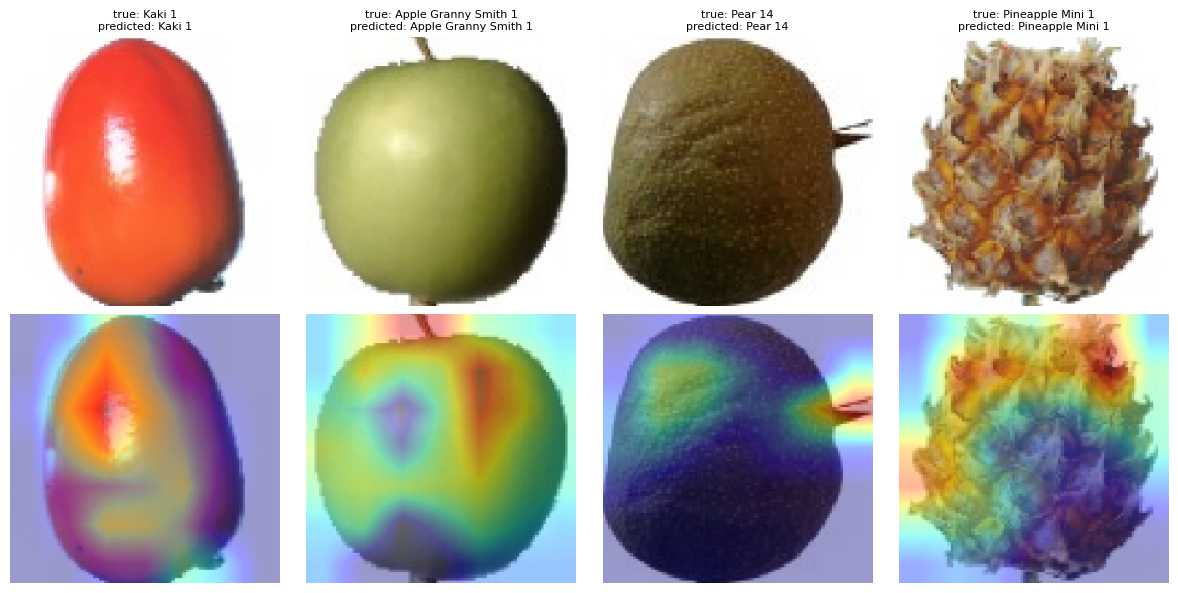

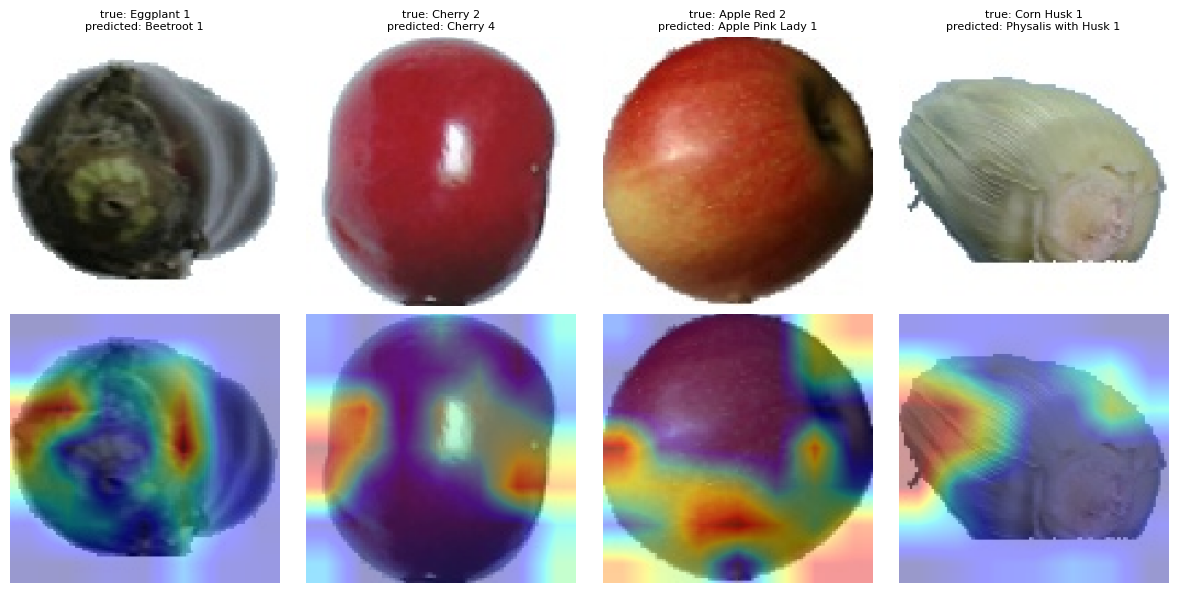

In [101]:
def make_gradcam(img, model, last_conv_name):
    x = tf.cast(img[None], tf.float32)
    if preprocess is not None:
        x = preprocess(x)
    # a model that outputs both the last conv layer and the final prediction
    grad_model = tf.keras.Model(model.input, [model.get_layer(last_conv_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(x)
        class_idx = tf.argmax(preds[0])
        score = preds[:, class_idx]                       # score of the predicted class
    grads = tape.gradient(score, conv_out)                # how much each feature map affects that score
    weights = tf.reduce_mean(grads, axis=(1, 2))          # one importance weight per feature map
    heat = tf.reduce_sum(conv_out * weights[:, None, None, :], axis=-1)[0]
    heat = tf.nn.relu(heat)                               # keep only areas that support the prediction
    heat = heat / (tf.reduce_max(heat) + 1e-8)            # scale to 0-1
    return heat.numpy(), int(class_idx)

def show_gradcam(indices, filename):
    fig, axes = plt.subplots(2, len(indices), figsize=(3 * len(indices), 6), squeeze=False)
    for col, i in enumerate(indices):
        img = tf.keras.utils.img_to_array(tf.keras.utils.load_img(test_ds.file_paths[i], target_size=IMG))
        heat, pred = make_gradcam(img, model, last_conv)
        heat = tf.image.resize(heat[..., None], IMG).numpy()[..., 0]
        axes[0, col].imshow(img.astype("uint8")); axes[0, col].axis("off")
        axes[0, col].set_title(f"true: {class_names[y_true[i]]}\npredicted: {class_names[pred]}", fontsize=8)
        axes[1, col].imshow(img.astype("uint8"))
        axes[1, col].imshow(heat, cmap="jet", alpha=0.4); axes[1, col].axis("off")
    plt.tight_layout()
    plt.savefig(f"results/{filename}_{EXPERIMENT_NAME}.png", dpi=150)
    plt.show()

rng = np.random.default_rng(42)
correct = np.where(y_true == y_pred)[0]
wrong = np.where(y_true != y_pred)[0]
show_gradcam(rng.choice(correct, 4, replace=False), "gradcam_correct")
if len(wrong) > 0:
    show_gradcam(rng.choice(wrong, min(4, len(wrong)), replace=False), "gradcam_wrong")
else:
    print("No wrong predictions in this run.")

## Results Table

In [102]:
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))
results_df.to_csv("results/experiments.csv", index=False)

                               experiment  classes  val_acc  test_acc  minutes  train_acc     gap  val_loss  test_loss  altered_acc
          EfficientNetB0, no augmentation      269   0.9999    0.9947    159.2     0.9990 -0.0010    0.0013     0.0225       0.7383
             EfficientNetB0, augmentation      269   0.9994    0.9931    157.3     0.9962 -0.0031    0.0039     0.0276       0.8379
       EfficientNetB0, augmentation, 1e-4      269   0.9996    0.9953    149.0     0.9970 -0.0013    0.0056     0.0186       0.8225
   EfficientNetB0, augmentation, drop 0.5      269   0.9995    0.9920    148.4     0.9916 -0.0079    0.0055     0.0304       0.8368
                   ResNet50, augmentation      269   0.9994    0.9939    330.7     0.9980 -0.0013    0.0033     0.0225       0.7662
EfficientNetB0, augmentation, unfreeze 60      269   0.9999    0.9940    150.1     0.9972 -0.0027    0.0029     0.0235       0.8411
